In [1]:
from pathlib import Path
import yaml

ROOT = Path("..")
cfg = yaml.safe_load(open(ROOT / "configs/default.yaml"))
cfg["ingest"]

{'max_merge_gap_s': 1.0}

In [2]:
import pandas as pd
from datasets import load_dataset

ds = load_dataset(cfg["data"]["dataset"], split=cfg["data"]["hf_split"], streaming=True)
cols = ["id", "text", "segment_start_time", "segment_end_time"]
raw = pd.DataFrame(list(ds.select_columns(cols)))
print(raw.shape)
raw.head()

(2822, 4)


,id,text,segment_start_time,segment_end_time
0,uwb-atcc_TWR-34720N_001179_001375_PI,for clearance we have information lima,11.790000,13.750000
1,uwb-atcc_TWR-34720N_001666_001952_AT,el al five two two startup approved time four ...,16.660000,19.520000
2,uwb-atcc_TWR-34720N_002001_002559_AT,clearance to telaviv via voz one hotel departu...,20.010000,25.590000
3,uwb-atcc_TWR-34720N_002594_002669_AT,one four four,25.940001,26.690001
4,uwb-atcc_TWR-34720N_003268_003531_PI,cleared via voz one hotel,32.680000,35.310001


In [3]:
seg = raw.rename(columns={"id": "utt_id", "text": "ref_text",
                          "segment_start_time": "start", "segment_end_time": "end"})

parts = seg["utt_id"].str.rsplit("_", n=3, expand=True)
seg["recording_id"] = parts[0].str.removeprefix("uwb-atcc_")
seg["speaker"] = parts[3].map({"AT": "ATCO", "PI": "PILOT", "PIAT": "UNKNOWN"})
seg["source"] = "uwb_atcc"

seg = seg.sort_values(["recording_id", "start"]).reset_index(drop=True)
seg.head(10)

,utt_id,ref_text,start,end,recording_id,speaker,source
0,uwb-atcc_TWR-34720N_001179_001375_PI,for clearance we have information lima,11.790000,13.750000,TWR-34720N,PILOT,uwb_atcc
1,uwb-atcc_TWR-34720N_001666_001952_AT,el al five two two startup approved time four ...,16.660000,19.520000,TWR-34720N,ATCO,uwb_atcc
2,uwb-atcc_TWR-34720N_002001_002559_AT,clearance to telaviv via voz one hotel departu...,20.010000,25.590000,TWR-34720N,ATCO,uwb_atcc
3,uwb-atcc_TWR-34720N_002594_002669_AT,one four four,25.940001,26.690001,TWR-34720N,ATCO,uwb_atcc
4,uwb-atcc_TWR-34720N_003268_003531_PI,cleared via voz one hotel,32.680000,35.310001,TWR-34720N,PILOT,uwb_atcc
5,uwb-atcc_TWR-34720N_003568_003790_PI,departure runway one three,35.680000,37.910000,TWR-34720N,PILOT,uwb_atcc
6,uwb-atcc_TWR-34720N_003839_004090_PI,one four four two el al five,38.389999,40.910000,TWR-34720N,PILOT,uwb_atcc
7,uwb-atcc_TWR-34720N_004252_004326_AT,correct,42.520000,43.259998,TWR-34720N,ATCO,uwb_atcc
8,uwb-atcc_TWR-A5lZHJ_000000_000613_AT,csa three seven alfa runway three one cleared ...,0.000000,6.130000,TWR-A5lZHJ,ATCO,uwb_atcc
9,uwb-atcc_TWR-A5lZHJ_000649_000787_PI,runway three one cleared for takeoff,6.490000,7.870000,TWR-A5lZHJ,PILOT,uwb_atcc


In [4]:
print(seg["speaker"].value_counts(dropna=False))
print("recordings:", seg["recording_id"].nunique())
seg.groupby("recording_id").size().describe()

speaker
PILOT      1460
ATCO       1164
UNKNOWN     198
Name: count, dtype: int64
recordings: 677


count    677.000000
mean       4.168390
std        3.222701
min        1.000000
25%        2.000000
50%        3.000000
75%        5.000000
max       28.000000
dtype: float64

Matplotlib is building the font cache; this may take a moment.


count    540.000000
mean       2.193778
std        3.697398
min        0.000000
25%        0.317500
50%        0.755000
75%        2.452500
max       39.430000
Name: gap, dtype: float64


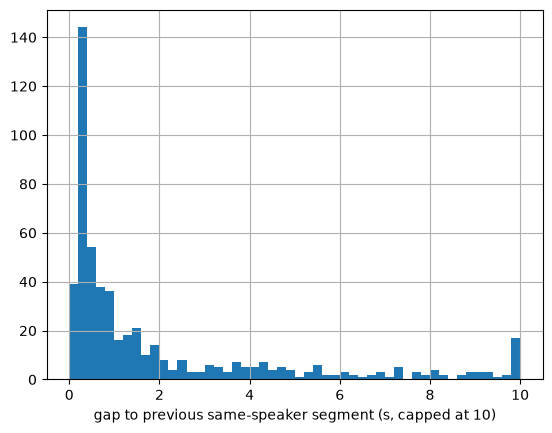

In [5]:
import matplotlib.pyplot as plt

prev = seg.groupby("recording_id").shift(1)
seg["gap"] = seg["start"] - prev["end"]
same_speaker = seg["speaker"] == prev["speaker"]

print(seg.loc[same_speaker, "gap"].describe())
seg.loc[same_speaker, "gap"].clip(upper=10).hist(bins=50)
plt.xlabel("gap to previous same-speaker segment (s, capped at 10)")
plt.show()

<h5>here i would like to take a moment to describe the histogram, there is a gap in tranmissions, between the tower and the pilot and in between there is cross attenuation of another pilot, which the llm is picking up as one conversation</h5>

In [6]:
MAX_GAP = cfg["ingest"]["max_merge_gap_s"]

new_turn = (
    (seg["recording_id"] != seg["recording_id"].shift())
    | (seg["speaker"] != seg["speaker"].shift())
    | (seg["gap"] > MAX_GAP)
)

seg["turn_id"] = new_turn.cumsum()
seg[["recording_id", "speaker", "start", "gap", "turn_id", "ref_text"]].head(20)

,recording_id,speaker,start,gap,turn_id,ref_text
0,TWR-34720N,PILOT,11.790000,NaN,1,for clearance we have information lima
1,TWR-34720N,ATCO,16.660000,2.910000,2,el al five two two startup approved time four ...
2,TWR-34720N,ATCO,20.010000,0.490000,2,clearance to telaviv via voz one hotel departu...
3,TWR-34720N,ATCO,25.940001,0.350000,2,one four four
4,TWR-34720N,PILOT,32.680000,5.990000,3,cleared via voz one hotel
5,TWR-34720N,PILOT,35.680000,0.369999,3,departure runway one three
6,TWR-34720N,PILOT,38.389999,0.480000,3,one four four two el al five
7,TWR-34720N,ATCO,42.520000,1.610001,4,correct
8,TWR-A5lZHJ,ATCO,0.000000,NaN,5,csa three seven alfa runway three one cleared ...
9,TWR-A5lZHJ,PILOT,6.490000,0.360000,6,runway three one cleared for takeoff


In [7]:
turns = (
    seg.groupby("turn_id")
       .agg(recording_id=("recording_id", "first"),
            speaker=("speaker", "first"),
            start=("start", "first"),
            end=("end", "last"),
            ref_text=("ref_text", " ".join),
            utt_ids=("utt_id", list),
            n_segments=("utt_id", "size"))
       .reset_index()
)
print(len(seg), "segments ->", len(turns), "turns")
turns["n_segments"].value_counts()

2822 segments -> 2511 turns


n_segments
1    2255
2     214
3      33
4       5
5       4
Name: count, dtype: int64

In [12]:
value_words = {
    "frequency": "decimal",
    "squawk": "squawk",
    "level": "flight level|altitude|feet",
    "heading": "heading",
    "speed": "speed",
    "runway":"runway"
}
for name, pattern in value_words.items():
    pairs[name] = pairs["atco_text"].str.contains(pattern)

pairs["has_value"] = pairs[list(value_words)].any(axis=1)
print(pairs[list(value_words)].sum())
print("pairs with a scored value:", pairs["has_value"].sum())

frequency     56
squawk        15
level          6
heading        0
speed         40
runway       415
dtype: int64
pairs with a scored value: 519


In [8]:
nxt = turns.groupby("recording_id").shift(-1)
# here i am trying to create a candidate pairs meaning one pilot comm followed by atc comm
is_pair = (turns["speaker"] == "ATCO") & (nxt["speaker"] == "PILOT")

pairs = pd.DataFrame({
    "recording_id": turns.loc[is_pair, "recording_id"],
    "atco_turn_id": turns.loc[is_pair, "turn_id"],
    "pilot_turn_id": nxt.loc[is_pair, "turn_id"].astype(int),
    "atco_text": turns.loc[is_pair, "ref_text"],
    "pilot_text": nxt.loc[is_pair, "ref_text"],
}).reset_index(drop=True)
print(len(pairs), "candidate pairs")
pairs.sample(10, random_state=0)

774 candidate pairs


,recording_id,atco_turn_id,pilot_turn_id,atco_text,pilot_text
369,TWR-VzZRsx,1195,1196,sky travel one one nine two taxi holding point...,lima sky travel one one nine
608,TWR-nckbfi,1964,1965,beair five five two runway one three clear to ...,clear to land one
401,TWR-Y4P9Qo,1307,1308,csa three foxtrot contact ruzyne ground one tw...,one two one nine csa three foxt
14,TWR-BBGy10,52,53,csa four kilo papa line up runway three one,line up runway three one csa four kilo papa
721,TWR-w7Tyjt,2329,2330,csa five victor papa contact ruzyne ground one...,one nine csa five victor papa
278,TWR-QYQvSQ,877,878,quality eight nine sierra continue,continue quality eight nine sierra and hold sh...
122,TWR-HW66KT,416,417,hello easy five four nine eight ruzyne tower l...,line up runway one three easy five four nine e...
742,TWR-xkHcZX,2399,2400,now wizz air five five six two standby,standby
386,TWR-Wrw6Pd,1246,1247,nor shuttle one five zero two ruyzne tower goo...,continue and reducing nor shuttle one five zer...
196,TWR-MDA783,638,639,csa seven five eight line up,line up one three csa seven five


In [9]:
import numpy as np

recs = np.sort(seg["recording_id"].unique())
rng = np.random.default_rng(cfg["split"]["seed"])
rng.shuffle(recs)
dev_recs = set(recs[: round(cfg["split"]["dev_fraction"] * len(recs))])

for df in (seg, turns, pairs):
    df["split"] = np.where(df["recording_id"].isin(dev_recs), "dev", "test")

pairs["split"].value_counts()

split
test    437
dev     337
Name: count, dtype: int64

In [14]:
out = ROOT / cfg["data"]["interim_dir"]
out.mkdir(parents=True, exist_ok=True)

pairs["pair_id"] = [f"p{i:04d}" for i in range(len(pairs))]

seg[seg["speaker"] != "UNKNOWN"].drop(columns="gap").to_parquet(out / "utterances.parquet", index=False)
turns[turns["speaker"] != "UNKNOWN"].to_parquet(out / "turns.parquet", index=False)
pairs.to_parquet(out / "candidate_pairs.parquet", index=False)
print(pairs.groupby("split").size())

split
dev     337
test    437
dtype: int64
